### Cell 1 — Import thư viện & cấu hình

In [1]:
import os, re, sys, glob, json, time, warnings, importlib
import numpy as np
import pandas as pd
import joblib

warnings.filterwarnings("ignore")

INPUT_ROOT = "/kaggle/input"
WORK_DIR   = "/kaggle/working"
OUT_DIR    = f"{WORK_DIR}/processed"   # dữ liệu đã xử lý (bàn giao cho Người B)
MODEL_DIR  = f"{WORK_DIR}/models"      # mô hình baseline
RESULT_DIR = f"{WORK_DIR}/results"     # kết quả đánh giá
for d in (OUT_DIR, MODEL_DIR, RESULT_DIR):
    os.makedirs(d, exist_ok=True)
sys.path.insert(0, WORK_DIR)           # để import được metrics.py

SEED = 42
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15      # Test = 0.15 còn lại (chia theo thứ tự thời gian)

def norm(c):
    return re.sub(r"[^a-z0-9]", "", str(c).lower())

# Tên cột chuẩn -> các biến thể tên có thể gặp ở các phiên bản CIC-IDS2017
ALIASES = {
    "flow_id":   ["flowid"],
    "src_ip":    ["sourceip", "srcip"],
    "dst_ip":    ["destinationip", "dstip"],
    "src_port":  ["sourceport", "srcport"],
    "dst_port":  ["destinationport", "dstport"],
    "timestamp": ["timestamp"],
    "label":     ["label"],
}
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.1.3


### Cell 2 — Tìm file & kiểm tra dataset có đủ cột cần thiết

In [2]:
files = sorted(glob.glob(f"{INPUT_ROOT}/**/*.parquet", recursive=True))
if not files:
    files = sorted(glob.glob(f"{INPUT_ROOT}/**/*.csv", recursive=True))
assert files, "Không thấy file .parquet/.csv trong /kaggle/input -> kiểm tra lại bước Add Input."

print(f"Tìm thấy {len(files)} file:")
for f in files:
    print(f"  {os.path.getsize(f)/1e6:8.1f} MB  {f}")

def read_one(f):
    if f.endswith(".parquet"):
        d = pd.read_parquet(f)
    else:
        d = pd.read_csv(f, encoding="latin-1", low_memory=False)
    d.columns = [str(c).strip() for c in d.columns]
    return d

sample = read_one(files[0])
print(f"\nFile đầu tiên: {os.path.basename(files[0])} -> {sample.shape[0]:,} dòng, {sample.shape[1]} cột")
print(list(sample.columns))

cols_norm = {norm(c) for c in sample.columns}
print("\nKiểm tra các cột bắt buộc:")
for need, key in [("Timestamp (bắt buộc để chia theo thời gian)", "timestamp"),
                  ("Source IP (cần cho đồ thị của Người B)", "src_ip"),
                  ("Destination IP (cần cho đồ thị của Người B)", "dst_ip"),
                  ("Label", "label")]:
    ok = any(n in cols_norm for n in ALIASES[key])
    print(f"  [{'OK' if ok else 'THIẾU'}] {need}")

Tìm thấy 8 file:
      96.1 MB  /kaggle/input/datasets/lkhangtannl/cic-ids2017tl/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
     101.9 MB  /kaggle/input/datasets/lkhangtannl/cic-ids2017tl/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
      75.4 MB  /kaggle/input/datasets/lkhangtannl/cic-ids2017tl/Friday-WorkingHours-Morning.pcap_ISCX.csv
     268.6 MB  /kaggle/input/datasets/lkhangtannl/cic-ids2017tl/Monday-WorkingHours.pcap_ISCX.csv
     108.7 MB  /kaggle/input/datasets/lkhangtannl/cic-ids2017tl/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
      92.0 MB  /kaggle/input/datasets/lkhangtannl/cic-ids2017tl/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
     174.7 MB  /kaggle/input/datasets/lkhangtannl/cic-ids2017tl/Tuesday-WorkingHours.pcap_ISCX.csv
     285.6 MB  /kaggle/input/datasets/lkhangtannl/cic-ids2017tl/Wednesday-workingHours.pcap_ISCX.csv

File đầu tiên: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv -> 225,745 dòng, 85 cột
['Flow ID', 'Sour

### Cell 3 — Tải & gộp toàn bộ file

In [3]:
parts = []
for f in files:
    d = read_one(f)
    d["source_file"] = os.path.basename(f)
    print(f"{os.path.basename(f):60s} {d.shape[0]:>10,} dòng")
    parts.append(d)
df = pd.concat(parts, ignore_index=True, sort=False)
del parts
print(f"\nTổng: {df.shape[0]:,} dòng x {df.shape[1]} cột | RAM ~ {df.memory_usage(deep=True).sum()/1e9:.2f} GB")

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                225,745 dòng
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv            286,467 dòng
Friday-WorkingHours-Morning.pcap_ISCX.csv                       191,033 dòng
Monday-WorkingHours.pcap_ISCX.csv                               529,918 dòng
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv     288,602 dòng
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv          458,968 dòng
Tuesday-WorkingHours.pcap_ISCX.csv                              445,909 dòng
Wednesday-workingHours.pcap_ISCX.csv                            692,703 dòng

Tổng: 3,119,345 dòng x 86 cột | RAM ~ 3.26 GB


### Cell 4 — Xác định cột, chuẩn hóa nhãn và Timestamp

In [4]:
# --- 4.1 Xác định các cột định danh / thời gian / nhãn ---
colmap = {}
for canon, names in ALIASES.items():
    for c in df.columns:
        if norm(c) in names:
            colmap[canon] = c
            break
print("Ánh xạ cột:", colmap)

assert "timestamp" in colmap, ("Dataset KHÔNG có cột Timestamp -> không thể chia theo thời gian đúng yêu cầu. "
                               "Cần dùng bản CIC-IDS2017 có metadata (xem hướng dẫn ở câu 1).")
assert "label" in colmap, "Không tìm thấy cột Label."
if "src_ip" not in colmap or "dst_ip" not in colmap:
    print("CẢNH BÁO: thiếu Source/Destination IP -> Người B sẽ không dựng được đồ thị Node = IP.")

# --- 4.2 Chuẩn hóa nhãn ---
LABEL, TS = colmap["label"], colmap["timestamp"]
df = df.dropna(subset=[LABEL, TS]).reset_index(drop=True)

def clean_label(s):
    s = re.sub(r"\s*[^\x20-\x7E]+\s*", " - ", str(s))   # ký tự lỗi mã hóa ở 'Web Attack � Brute Force'
    return re.sub(r"\s+", " ", s).strip()

label_map = {v: clean_label(v) for v in df[LABEL].unique()}
df["label_multi"] = df[LABEL].map(label_map)
df["label_bin"] = (df["label_multi"].str.lower() != "benign").astype("int8")   # 0 = Normal, 1 = Attack
print("\nPhân bố nhãn (toàn bộ):")
print(df["label_multi"].value_counts().to_string())

# --- 4.3 Chuẩn hóa Timestamp ---
if not pd.api.types.is_datetime64_any_dtype(df[TS]):
    try:
        ts = pd.to_datetime(df[TS], errors="coerce", format="mixed", dayfirst = True)
    except (ValueError, TypeError):
        ts = pd.to_datetime(df[TS], errors="coerce", dayfirst = True)
    # Bản CSV gốc ghi giờ dạng 12h không có AM/PM: các giờ 1..7 thực chất là 13..19 giờ
    ts = ts.where(~ts.dt.hour.between(1, 7), ts + pd.Timedelta(hours=12))
    df[TS] = ts
n_bad = int(df[TS].isna().sum())
if n_bad:
    print(f"Bỏ {n_bad:,} dòng có Timestamp không đọc được")
    df = df.dropna(subset=[TS]).reset_index(drop=True)

chk = df.groupby("source_file")[TS].agg(["min", "max"])
chk["giờ_min"] = df.groupby("source_file")[TS].apply(lambda s: s.dt.hour.min())
chk["giờ_max"] = df.groupby("source_file")[TS].apply(lambda s: s.dt.hour.max())
print("\nKhoảng thời gian từng file (kỳ vọng: 03/07 -> 07/07/2017, giờ ~ 8..17):")
print(chk.to_string())

Ánh xạ cột: {'flow_id': 'Flow ID', 'src_ip': 'Source IP', 'dst_ip': 'Destination IP', 'src_port': 'Source Port', 'dst_port': 'Destination Port', 'timestamp': 'Timestamp', 'label': 'Label'}

Phân bố nhãn (toàn bộ):
label_multi
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack - Brute Force         1507
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11

Khoảng thời gian từng file (kỳ vọng: 03/07 -> 07/07/2017, giờ ~ 8..17):
                                                                            min                 max  giờ_min  giờ_max
source_file  

### Cell 5 — Làm sạch: loại cột định danh, xử lý Inf/NaN, loại dòng trùng

In [5]:
# --- 5.1 Xác định cột đặc trưng (loại bỏ cột định danh) ---
# Giữ lại 'Destination Port' và 'Protocol' làm đặc trưng; bỏ Flow ID, IP, Source Port (cổng tạm thời), Timestamp, nhãn.
drop_as_feature = {colmap[k] for k in colmap if k != "dst_port"}
drop_as_feature |= {"label_multi", "label_bin", "source_file"}
feature_cols = [c for c in df.columns if c not in drop_as_feature]

# Cột trùng lặp (vd. 'Fwd Header Length.1' của bản CSV gốc)
dups = [c for c in feature_cols if c.endswith(".1") and c[:-2] in feature_cols and df[c].equals(df[c[:-2]])]
feature_cols = [c for c in feature_cols if c not in dups]
print("Cột trùng bị loại:", dups)

# --- 5.2 Ép kiểu số, đổi Inf -> NaN, hạ về float32 ---
report = []
for c in feature_cols:
    s = pd.to_numeric(df[c], errors="coerce")
    n_inf = int(np.isinf(s).sum())
    s = s.replace([np.inf, -np.inf], np.nan).astype("float32")
    s = s.replace([np.inf, -np.inf], np.nan)            # phòng trường hợp tràn khi ép sang float32
    n_nan = int(s.isna().sum())
    if n_inf or n_nan:
        report.append((c, n_inf, n_nan))
    df[c] = s
if report:
    print("\nCột có Inf/NaN (số Inf, số NaN sau khi đổi Inf -> NaN):")
    for c, i, n in report:
        print(f"  {c:35s} inf={i:>8,}  nan={n:>8,}")

all_nan = [c for c in feature_cols if df[c].isna().all()]
feature_cols = [c for c in feature_cols if c not in all_nan]
print("Cột toàn NaN bị loại:", all_nan)

# --- 5.3 Loại bản ghi trùng lặp hoàn toàn ---
before = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "source_file"]).reset_index(drop=True)
print(f"\nBỏ {before - len(df):,} dòng trùng lặp hoàn toàn -> còn {len(df):,} dòng, {len(feature_cols)} đặc trưng")
# NaN còn lại sẽ được điền bằng median của tập TRAIN ở bước 7 (tránh rò rỉ thông tin).

Cột trùng bị loại: ['Fwd Header Length.1']

Cột có Inf/NaN (số Inf, số NaN sau khi đổi Inf -> NaN):
  Flow Bytes/s                        inf=   1,509  nan=   2,867
  Flow Packets/s                      inf=   2,867  nan=   2,867
Cột toàn NaN bị loại: []

Bỏ 203 dòng trùng lặp hoàn toàn -> còn 2,830,540 dòng, 78 đặc trưng


### Cell 6 — Chia Train / Validation / Test theo thời gian (70 / 15 / 15)

In [6]:
# SPLIT_MODE (mọi chế độ đều giữ thứ tự thời gian, KHÔNG xáo trộn):
#   "per_file_label": với mỗi (file, loại nhãn), sắp xếp theo thời gian rồi lấy 70% đầu -> Train, 15% kế -> Val, 15% cuối -> Test
#   "per_file"      : với mỗi file, chia 70/15/15 theo thời gian (loại tấn công nằm ở khung giờ sáng thường rơi hết vào Train)
#   "global"        : sắp xếp toàn bộ tuần theo thời gian rồi cắt 70/15/15 (nhiều loại tấn công chỉ xuất hiện ở Val/Test)
SPLIT_MODE = "per_file_label"

df = df.sort_values(TS, kind="mergesort").reset_index(drop=True)
n = len(df)
ts_all = df[TS]
assert ts_all.is_monotonic_increasing

if SPLIT_MODE == "global":
    groups = {"global": np.arange(n)}
elif SPLIT_MODE == "per_file":
    groups = dict(df.groupby("source_file").indices)
elif SPLIT_MODE == "per_file_label":
    groups = {f"{f} | {l}": idx for (f, l), idx in df.groupby(["source_file", "label_multi"]).indices.items()}
else:
    raise ValueError("SPLIT_MODE phải là 'per_file_label', 'per_file' hoặc 'global'")

is_train = np.zeros(n, dtype=bool)
is_val = np.zeros(n, dtype=bool)
is_test = np.zeros(n, dtype=bool)
split_boundaries = {}
for gname, idx in groups.items():          # idx: vị trí các dòng của nhóm, đã theo thứ tự thời gian
    k = len(idx)
    i1, i2 = int(k * TRAIN_FRAC), int(k * (TRAIN_FRAC + VAL_FRAC))
    is_train[idx[:i1]] = True
    is_val[idx[i1:i2]] = True
    is_test[idx[i2:]] = True
    split_boundaries[gname] = {"n": int(k), "val_starts": str(ts_all.iloc[idx[i1]]), "test_starts": str(ts_all.iloc[idx[i2]])}

assert is_train.sum() + is_val.sum() + is_test.sum() == n
assert not (is_train & is_val).any() and not (is_train & is_test).any() and not (is_val & is_test).any()
print("SPLIT_MODE =", SPLIT_MODE, "| số nhóm:", len(groups))

rows = []
for name, m in [("train", is_train), ("val", is_val), ("test", is_test)]:
    s = df.loc[m]
    rows.append({"split": name, "n": len(s), "from": s[TS].min(), "to": s[TS].max(),
                 "n_attack": int(s["label_bin"].sum()), "attack_%": round(100 * s["label_bin"].mean(), 2)})
print(pd.DataFrame(rows).to_string(index=False))

split_name = np.select([is_train, is_val, is_test], ["1_train", "2_val", "3_test"], default="")
ct = pd.crosstab(df["label_multi"], split_name)
print("\nSố mẫu theo loại nhãn và theo tập:")
print(ct.to_string())

all_types = set(df["label_multi"])
miss_test = sorted(all_types - set(df.loc[is_test, "label_multi"]))
unseen = sorted(set(df.loc[is_val | is_test, "label_multi"]) - set(df.loc[is_train, "label_multi"]))
print("\nLoại nhãn KHÔNG có trong Test :", miss_test if miss_test else "không có")
print("Loại nhãn có ở Val/Test nhưng không có ở Train:", unseen if unseen else "không có")

for name, m in [("train", is_train), ("val", is_val), ("test", is_test)]:
    assert df.loc[m, "label_bin"].nunique() == 2, f"Tập {name} chỉ có 1 lớp -> cần xem lại tỉ lệ chia."

SPLIT_MODE = per_file_label | số nhóm: 22
split       n                from                  to  n_attack  attack_%
train 1981368 2017-07-03 08:55:58 2017-07-07 16:15:00    390345      19.7
  val  424581 2017-07-03 14:06:20 2017-07-07 16:38:00     83647      19.7
 test  424591 2017-07-03 15:47:50 2017-07-07 17:02:00     83653      19.7

Số mẫu theo loại nhãn và theo tập:
col_0                       1_train   2_val  3_test
label_multi                                        
BENIGN                      1591023  340934  340938
Bot                            1376     295     295
DDoS                          89618   19204   19205
DoS GoldenEye                  7205    1544    1544
DoS Hulk                     161750   34661   34661
DoS Slowhttptest               3849     825     825
DoS slowloris                  4057     869     870
FTP-Patator                    5556    1191    1191
Heartbleed                        7       2       2
Infiltration                     25       5       6
Po

### Cell 7 — Điền NaN & chuẩn hóa (StandardScaler chỉ fit trên Train)

In [7]:
from sklearn.preprocessing import StandardScaler

# --- 7.1 Median để điền NaN: chỉ tính trên TRAIN ---
medians = df.loc[is_train, feature_cols].median()
tr_filled = df.loc[is_train, feature_cols].fillna(medians)

# --- 7.2 Loại đặc trưng hằng số (độ lệch chuẩn = 0 trên TRAIN) ---
std_tr = tr_filled.std()
const_cols = std_tr[(std_tr == 0) | std_tr.isna()].index.tolist()
final_features = [c for c in feature_cols if c not in const_cols]
print(f"Loại {len(const_cols)} đặc trưng hằng số: {const_cols}")
print(f"Số đặc trưng cuối cùng: {len(final_features)}")

# --- 7.3 Scaler: FIT chỉ trên TRAIN, TRANSFORM cho Train/Val/Test ---
scaler = StandardScaler()
scaler.fit(tr_filled[final_features])
del tr_filled

def transform(mask):
    part = df.loc[mask, final_features].fillna(medians[final_features])
    return scaler.transform(part).astype("float32")

X = {"train": transform(is_train), "val": transform(is_val), "test": transform(is_test)}
masks = {"train": is_train, "val": is_val, "test": is_test}

for k, v in X.items():
    assert np.isfinite(v).all(), f"Còn NaN/Inf ở tập {k}"
print("\nTrain sau chuẩn hóa: mean ~", float(np.abs(X['train'].mean(axis=0)).max()),
      "| std ~", float(X['train'].std(axis=0).mean()))
print({k: v.shape for k, v in X.items()})

Loại 8 đặc trưng hằng số: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Số đặc trưng cuối cùng: 70

Train sau chuẩn hóa: mean ~ 6.77700171536344e-08 | std ~ 1.0
{'train': (1981368, 70), 'val': (424581, 70), 'test': (424591, 70)}


### Cell 8 — Lưu dữ liệu đã xử lý & cấu hình (phục vụ Handover 1)

In [8]:
meta_cols = {k: colmap[k] for k in ["flow_id", "src_ip", "dst_ip", "src_port", "dst_port", "timestamp"] if k in colmap}
rename = {v: k for k, v in meta_cols.items()}

for name in ["train", "val", "test"]:
    # đặc trưng đã chuẩn hóa
    pd.DataFrame(X[name], columns=final_features).to_parquet(f"{OUT_DIR}/{name}_features.parquet", index=False)
    # metadata + nhãn (cùng thứ tự dòng với file features) -> Người B dùng để dựng đồ thị
    meta = df.loc[masks[name], list(meta_cols.values()) + ["label_multi", "label_bin", "source_file"]]
    meta = meta.rename(columns=rename).reset_index(drop=True)
    meta.to_parquet(f"{OUT_DIR}/{name}_meta.parquet", index=False)

# Bộ tiền xử lý: dùng lại y hệt cho dữ liệu Streaming (Inf->NaN, fillna(medians), scaler.transform)
joblib.dump({"feature_cols": final_features, "medians": medians[final_features],
             "scaler": scaler}, f"{OUT_DIR}/preprocessor.joblib")

config = {
    "split": {"train_frac": TRAIN_FRAC, "val_frac": VAL_FRAC, "test_frac": round(1 - TRAIN_FRAC - VAL_FRAC, 4),
              "mode": SPLIT_MODE, "boundaries": split_boundaries,
              "n_train": int(is_train.sum()), "n_val": int(is_val.sum()), "n_test": int(is_test.sum())},
    "label_binary": {"0": "Normal (Benign)", "1": "Attack"},
    "label_multi_classes": sorted(df["label_multi"].unique().tolist()),
    "meta_columns": list(meta_cols.keys()),
    "n_features": len(final_features),
    "features": final_features,
    "dropped_constant_features": const_cols,
    "scaler": "StandardScaler (fit trên Train)",
    "nan_strategy": "Inf->NaN; điền median của Train",
    "seed": SEED,
}
with open(f"{OUT_DIR}/config.json", "w", encoding="utf-8") as fh:
    json.dump(config, fh, ensure_ascii=False, indent=2)

print("Đã lưu:")
for f in sorted(os.listdir(OUT_DIR)):
    print(f"  {os.path.getsize(os.path.join(OUT_DIR, f))/1e6:8.1f} MB  {f}")

Đã lưu:
       0.0 MB  config.json
       0.0 MB  preprocessor.joblib
      37.9 MB  test_features.parquet
       6.2 MB  test_meta.parquet
     171.7 MB  train_features.parquet
      27.7 MB  train_meta.parquet
      37.0 MB  val_features.parquet
       6.1 MB  val_meta.parquet


### Cell 9 — Viết file metrics.py (F1, Recall, Confusion Matrix)

In [9]:
%%writefile /kaggle/working/metrics.py
"""
metrics.py - Thư viện đánh giá dùng chung cho cả nhóm (RF, XGBoost, GraphSAGE, MLP).

Quy ước nhãn nhị phân: 0 = Normal (Benign), 1 = Attack (lớp dương).
Các chỉ số chính: F1-score, Recall, Confusion Matrix. Bổ sung: Precision, Macro-F1, FPR, FNR.

Cách dùng:
    import metrics
    res = metrics.evaluate_and_save("random_forest", "test", y_true, y_pred, y_score,
                                    label_multi=label_multi, out_dir="results")
"""
import json
import os

import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)

NORMAL, ATTACK = 0, 1
CLASS_NAMES = ["Normal", "Attack"]


def compute_metrics(y_true, y_pred, y_score=None):
    """Chỉ số cho bài toán nhị phân Normal/Attack. Trả về dict (có thể ghi JSON)."""
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[NORMAL, ATTACK])
    tn, fp, fn, tp = (int(v) for v in cm.ravel())
    res = {
        "n_samples": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, pos_label=ATTACK, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, pos_label=ATTACK, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, pos_label=ATTACK, zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", labels=[NORMAL, ATTACK], zero_division=0)),
        "macro_recall": float(recall_score(y_true, y_pred, average="macro", labels=[NORMAL, ATTACK], zero_division=0)),
        "fpr": float(fp / (fp + tn)) if (fp + tn) else 0.0,   # Normal bị báo nhầm là Attack
        "fnr": float(fn / (fn + tp)) if (fn + tp) else 0.0,   # Attack bị bỏ sót
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "confusion_matrix": cm.tolist(),                      # [[TN, FP], [FN, TP]]
    }
    if y_score is not None and len(np.unique(y_true)) == 2:
        res["roc_auc"] = float(roc_auc_score(y_true, y_score))
        res["pr_auc"] = float(average_precision_score(y_true, y_score))
    return res


def compute_multiclass_metrics(y_true, y_pred, labels=None):
    """Chỉ số đa lớp (dùng cho phân tích lỗi theo loại tấn công). Nhãn là chuỗi hoặc số."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    if labels is None:
        labels = sorted(set(y_true) | set(y_pred))
    p = precision_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    r = recall_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    f = f1_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    support = pd.Series(y_true).value_counts().reindex(labels).fillna(0).astype(int).to_numpy()
    per_class = pd.DataFrame({"class": labels, "precision": p, "recall": r, "f1": f, "support": support})
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)),
        "per_class": per_class,
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels),
        "labels": list(labels),
    }


def detection_rate_by_type(label_multi, y_pred):
    """Với mỗi loại nhãn gốc: tỉ lệ bị dự đoán là Attack.
    Dòng Benign chính là False Positive Rate; các dòng tấn công chính là Recall theo từng loại."""
    d = pd.DataFrame({"label": np.asarray(label_multi), "pred_attack": np.asarray(y_pred).astype(int)})
    g = d.groupby("label")["pred_attack"].agg(n="size", predicted_attack="sum")
    g["rate_predicted_attack"] = g["predicted_attack"] / g["n"]
    return g.reset_index().sort_values("n", ascending=False).reset_index(drop=True)


def plot_confusion_matrix(cm, class_names=None, title="Confusion Matrix", normalize=False, save_path=None, show=True):
    import matplotlib
    import matplotlib.pyplot as plt
    cm = np.asarray(cm)
    class_names = class_names or CLASS_NAMES
    data = cm.astype(float)
    if normalize:
        data = data / np.maximum(data.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(5, 4.2))
    im = ax.imshow(data, cmap="Blues")
    ax.set_xticks(range(len(class_names)), labels=class_names)
    ax.set_yticks(range(len(class_names)), labels=class_names)
    ax.set_xlabel("Dự đoán (Predicted)")
    ax.set_ylabel("Thực tế (Actual)")
    ax.set_title(title)
    thresh = data.max() / 2 if data.max() > 0 else 0.5
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            txt = f"{data[i, j]:.2%}" if normalize else f"{int(cm[i, j]):,}"
            ax.text(j, i, txt, ha="center", va="center", color="white" if data[i, j] > thresh else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150)
    if show:
        plt.show()
    plt.close(fig)


def evaluate_and_save(model_name, split_name, y_true, y_pred, y_score=None, label_multi=None,
                      out_dir="results", verbose=True):
    """Tính chỉ số, in kết quả, lưu JSON + ảnh Confusion Matrix (+ CSV theo loại tấn công nếu có label_multi)."""
    os.makedirs(out_dir, exist_ok=True)
    tag = f"{model_name}_{split_name}"
    res = compute_metrics(y_true, y_pred, y_score)
    res.update({"model": model_name, "split": split_name})
    with open(os.path.join(out_dir, f"{tag}_metrics.json"), "w", encoding="utf-8") as fh:
        json.dump(res, fh, ensure_ascii=False, indent=2)
    plot_confusion_matrix(res["confusion_matrix"], title=f"{model_name} - {split_name}",
                          save_path=os.path.join(out_dir, f"{tag}_confusion_matrix.png"), show=verbose)
    if label_multi is not None:
        detection_rate_by_type(label_multi, y_pred).to_csv(
            os.path.join(out_dir, f"{tag}_detection_by_type.csv"), index=False)
    if verbose:
        print(f"[{tag}] F1={res['f1']:.4f} | Recall={res['recall']:.4f} | Precision={res['precision']:.4f} | "
              f"Macro-F1={res['macro_f1']:.4f} | FPR={res['fpr']:.4f} | CM(TN,FP,FN,TP)="
              f"({res['tn']:,}, {res['fp']:,}, {res['fn']:,}, {res['tp']:,})")
    return res

Writing /kaggle/working/metrics.py


### Cell 10 — Nạp lại dữ liệu đã lưu (kiểm tra đúng thứ Người B sẽ nhận)

In [10]:
import metrics
importlib.reload(metrics)

def load_split(name):
    X_ = pd.read_parquet(f"{OUT_DIR}/{name}_features.parquet")
    m_ = pd.read_parquet(f"{OUT_DIR}/{name}_meta.parquet")
    return X_, m_["label_bin"].to_numpy(), m_["label_multi"].to_numpy()

Xtr, ytr, ltr = load_split("train")
Xva, yva, lva = load_split("val")
Xte, yte, lte = load_split("test")
print("Train/Val/Test:", Xtr.shape, Xva.shape, Xte.shape)
print("Tỉ lệ Attack - Train/Val/Test:", ytr.mean().round(4), yva.mean().round(4), yte.mean().round(4))

Train/Val/Test: (1981368, 70) (424581, 70) (424591, 70)
Tỉ lệ Attack - Train/Val/Test: 0.197 0.197 0.197


### Cell 11 — Baseline 1: Random Forest

Huấn luyện RF xong sau 5.2 phút


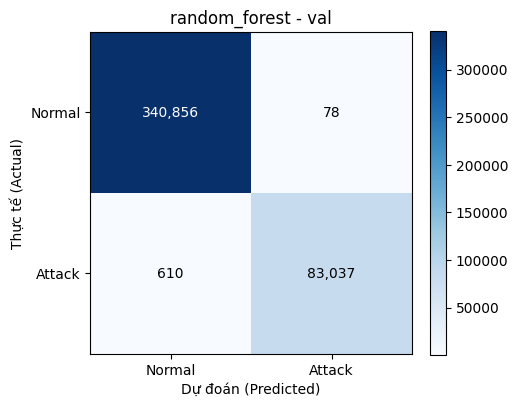

[random_forest_val] F1=0.9959 | Recall=0.9927 | Precision=0.9991 | Macro-F1=0.9974 | FPR=0.0002 | CM(TN,FP,FN,TP)=(340,856, 78, 610, 83,037)


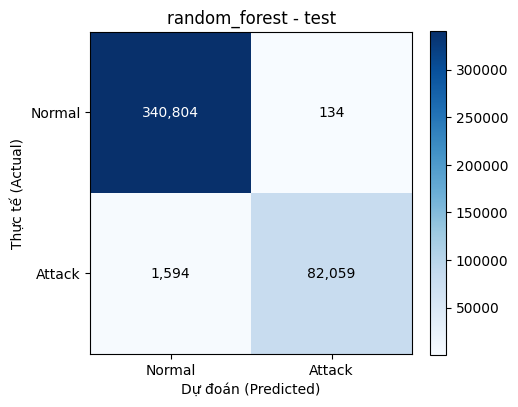

[random_forest_test] F1=0.9896 | Recall=0.9809 | Precision=0.9984 | Macro-F1=0.9935 | FPR=0.0004 | CM(TN,FP,FN,TP)=(340,804, 134, 1,594, 82,059)
Kích thước file mô hình: 13.9 MB

Top 10 đặc trưng quan trọng (RF):
Destination Port               0.069285
Packet Length Std              0.050695
Avg Bwd Segment Size           0.049180
Average Packet Size            0.047352
Bwd Packet Length Min          0.043728
Init_Win_bytes_forward         0.040119
Bwd Packet Length Mean         0.039340
Packet Length Variance         0.039024
Init_Win_bytes_backward        0.038630
Total Length of Fwd Packets    0.038233


In [11]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=2,                 # hạn chế cây quá sâu -> file mô hình nhỏ hơn, dự đoán nhanh hơn
    class_weight="balanced_subsample",  # bù mất cân bằng lớp
    n_jobs=-1,
    random_state=SEED,
)
t0 = time.time()
rf.fit(Xtr, ytr)
rf_train_time = time.time() - t0
print(f"Huấn luyện RF xong sau {rf_train_time/60:.1f} phút")

rf_results = {}
for name, X_, y_, l_ in [("val", Xva, yva, lva), ("test", Xte, yte, lte)]:
    proba = rf.predict_proba(X_)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rf_results[name] = metrics.evaluate_and_save("random_forest", name, y_, pred, proba,
                                                 label_multi=l_, out_dir=RESULT_DIR)

joblib.dump(rf, f"{MODEL_DIR}/random_forest.joblib", compress=3)
with open(f"{RESULT_DIR}/random_forest_train_info.json", "w") as fh:
    json.dump({"train_time_sec": rf_train_time, "params": rf.get_params()}, fh, indent=2, default=str)
print(f"Kích thước file mô hình: {os.path.getsize(f'{MODEL_DIR}/random_forest.joblib')/1e6:.1f} MB")

imp = pd.Series(rf.feature_importances_, index=Xtr.columns).sort_values(ascending=False)
imp.to_csv(f"{RESULT_DIR}/random_forest_feature_importance.csv", header=["importance"])
print("\nTop 10 đặc trưng quan trọng (RF):")
print(imp.head(10).to_string())

### Cell 12 — Baseline 2: XGBoost

scale_pos_weight = 4.076
[0]	validation_0-aucpr:0.98878
[50]	validation_0-aucpr:0.99874
[100]	validation_0-aucpr:0.99937
[150]	validation_0-aucpr:0.99955
[200]	validation_0-aucpr:0.99964
[250]	validation_0-aucpr:0.99970
[256]	validation_0-aucpr:0.99971
Huấn luyện XGBoost xong sau 1.7 phút | best_iteration = 226


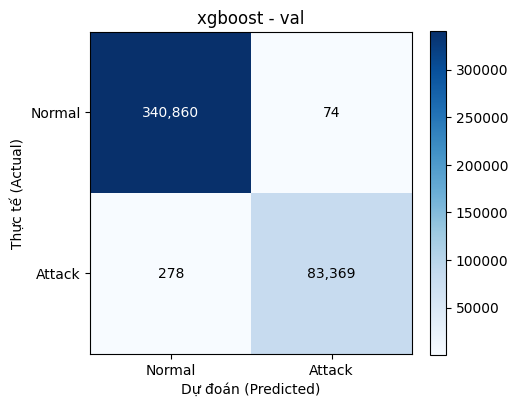

[xgboost_val] F1=0.9979 | Recall=0.9967 | Precision=0.9991 | Macro-F1=0.9987 | FPR=0.0002 | CM(TN,FP,FN,TP)=(340,860, 74, 278, 83,369)


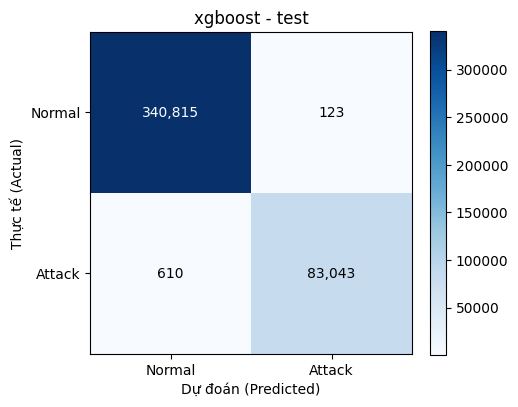

[xgboost_test] F1=0.9956 | Recall=0.9927 | Precision=0.9985 | Macro-F1=0.9973 | FPR=0.0004 | CM(TN,FP,FN,TP)=(340,815, 123, 610, 83,043)


In [12]:
import xgboost as xgb

n_neg, n_pos = int((ytr == 0).sum()), int((ytr == 1).sum())
spw = n_neg / n_pos                     # bù mất cân bằng lớp (chỉ tính trên Train)
print(f"scale_pos_weight = {spw:.3f}")

xgb_clf = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=spw,
    tree_method="hist",
    eval_metric="aucpr",
    early_stopping_rounds=30,           # dừng sớm dựa trên tập VALIDATION (không dùng Test)
    n_jobs=-1,
    random_state=SEED,
)
t0 = time.time()
xgb_clf.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=50)
xgb_train_time = time.time() - t0
print(f"Huấn luyện XGBoost xong sau {xgb_train_time/60:.1f} phút | best_iteration = {xgb_clf.best_iteration}")

for name, X_, y_, l_ in [("val", Xva, yva, lva), ("test", Xte, yte, lte)]:
    proba = xgb_clf.predict_proba(X_)[:, 1]
    pred = (proba >= 0.5).astype(int)
    metrics.evaluate_and_save("xgboost", name, y_, pred, proba, label_multi=l_, out_dir=RESULT_DIR)

xgb_clf.save_model(f"{MODEL_DIR}/xgboost.json")
joblib.dump(xgb_clf, f"{MODEL_DIR}/xgboost.joblib", compress=3)
with open(f"{RESULT_DIR}/xgboost_train_info.json", "w") as fh:
    json.dump({"train_time_sec": xgb_train_time, "best_iteration": int(xgb_clf.best_iteration),
               "params": xgb_clf.get_params()}, fh, indent=2, default=str)

### Cell 13 — Tổng hợp kết quả Baseline & danh sách file bàn giao

In [13]:
rows = []
for model in ["random_forest", "xgboost"]:
    info = json.load(open(f"{RESULT_DIR}/{model}_train_info.json"))
    for split in ["val", "test"]:
        r = json.load(open(f"{RESULT_DIR}/{model}_{split}_metrics.json"))
        rows.append({"model": model, "split": split, "f1": r["f1"], "recall": r["recall"], "precision": r["precision"],
                     "macro_f1": r["macro_f1"], "fpr": r["fpr"], "fnr": r["fnr"],
                     "tn": r["tn"], "fp": r["fp"], "fn": r["fn"], "tp": r["tp"],
                     "train_time_sec": round(info["train_time_sec"], 1)})
summary = pd.DataFrame(rows)
summary.to_csv(f"{RESULT_DIR}/baseline_summary.csv", index=False)
print(summary.round(4).to_string(index=False))

print("\nTỉ lệ bị dự đoán là Attack theo từng loại nhãn (tập TEST):")
for model in ["random_forest", "xgboost"]:
    d = pd.read_csv(f"{RESULT_DIR}/{model}_test_detection_by_type.csv")
    print(f"\n--- {model} ---")
    print(d.round(4).to_string(index=False))

print("\nCác file bàn giao trong /kaggle/working:")
for root, _, fs in os.walk(WORK_DIR):
    for f in sorted(fs):
        p = os.path.join(root, f)
        print(f"  {os.path.getsize(p)/1e6:9.1f} MB  {os.path.relpath(p, WORK_DIR)}")

        model split     f1  recall  precision  macro_f1    fpr    fnr     tn  fp   fn    tp  train_time_sec
random_forest   val 0.9959  0.9927     0.9991    0.9974 0.0002 0.0073 340856  78  610 83037           312.7
random_forest  test 0.9896  0.9809     0.9984    0.9935 0.0004 0.0191 340804 134 1594 82059           312.7
      xgboost   val 0.9979  0.9967     0.9991    0.9987 0.0002 0.0033 340860  74  278 83369           103.2
      xgboost  test 0.9956  0.9927     0.9985    0.9973 0.0004 0.0073 340815 123  610 83043           103.2

Tỉ lệ bị dự đoán là Attack theo từng loại nhãn (tập TEST):

--- random_forest ---
                     label      n  predicted_attack  rate_predicted_attack
                    BENIGN 340938               134                 0.0004
                  DoS Hulk  34661             33754                 0.9738
                  PortScan  23840             23777                 0.9974
                      DDoS  19205             19146                 0.9969
  